# 00.05 — ε: explore vs exploit

<div><span style="display:inline-block;background:#FF6B9A;color:white;font-weight:800;padding:4px 8px;border-radius:5px;margin:3px">EPSILON</span><span style="display:inline-block;background:#9C6ADE;color:white;font-weight:800;padding:4px 8px;border-radius:5px;margin:3px">EXPLORE</span><span style="display:inline-block;background:#2F80ED;color:white;font-weight:800;padding:4px 8px;border-radius:5px;margin:3px">EXPLOIT</span><span style="display:inline-block;background:#F58518;color:white;font-weight:800;padding:4px 8px;border-radius:5px;margin:3px">ACTION</span><span style="display:inline-block;background:#ECA82C;color:white;font-weight:800;padding:4px 8px;border-radius:5px;margin:3px">Q</span></div>

In [1]:
from pathlib import Path
import sys, numpy as np, pandas as pd, matplotlib.pyplot as plt
repo=Path.cwd()
if repo.name=="notebooks": repo=repo.parent
sys.path.insert(0,str(repo))
from lineworld import LineWorld
from visuals import *
legend()

<div style="border-left:10px solid #FF6B9A;background:#16181c;color:#f4f4f5;padding:14px 18px;border-radius:9px;margin:10px 0 14px 0"><div style="font-size:12px;font-weight:900;letter-spacing:.12em;color:#FF6B9A">EPSILON</div><div style="font-size:21px;font-weight:800;margin-top:4px">ε = probability of deliberate exploration</div><div style="font-size:15px;line-height:1.55;margin-top:8px">ε=.25 means about 25% of training decisions take a random valid action instead of the greedy Q choice.</div></div>

first 10: [0.62509547 0.8972138  0.77568569 0.22520719 0.30016628 0.87355345
 0.0052653  0.82122842 0.79706943 0.46793495]
fraction explore: 0.257


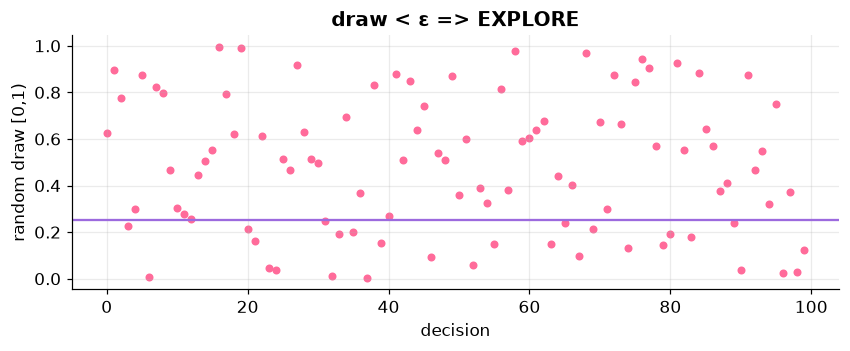

In [2]:
epsilon=.25; rng=np.random.default_rng(7); draws=rng.random(1000); explore=draws<epsilon
print("first 10:",draws[:10]); print("fraction explore:",explore.mean())
plt.figure(figsize=(9,3)); plt.scatter(range(100),draws[:100],s=18,color=COLORS["EPSILON"]); plt.axhline(epsilon,color=COLORS["EXPLORE"]); plt.ylabel("random draw [0,1)"); plt.xlabel("decision"); plt.title("draw < ε => EXPLORE"); plt.show()

NumPy random draws are floating-point values approximately uniform over **[0,1)**; they are not limited to one or two decimals.

<div style="border-left:10px solid #9C6ADE;background:#16181c;color:#f4f4f5;padding:14px 18px;border-radius:9px;margin:10px 0 14px 0"><div style="font-size:12px;font-weight:900;letter-spacing:.12em;color:#9C6ADE">EXPLORE</div><div style="font-size:21px;font-weight:800;margin-top:4px">env.action_space.sample()</div><div style="font-size:15px;line-height:1.55;margin-top:8px">Ask Gym’s declared action space for a random valid action. Here `Discrete(2)` gives either 0 LEFT or 1 RIGHT.</div></div>

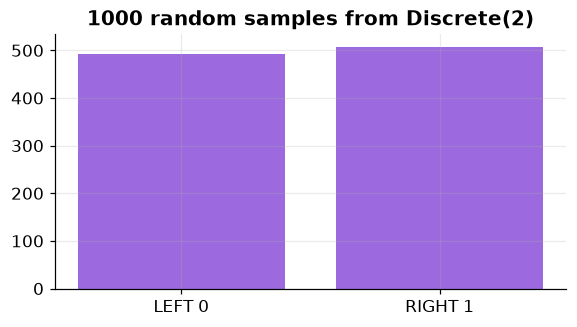

In [3]:
env=LineWorld(); x=[env.action_space.sample() for _ in range(1000)]; counts=pd.Series(x).value_counts().sort_index(); plt.figure(figsize=(6,3)); plt.bar(["LEFT 0","RIGHT 1"],counts.values,color=COLORS["EXPLORE"]); plt.title("1000 random samples from Discrete(2)"); plt.show()

τ² analogy: its action space is conceptually the valid tool/message actions and schemas available to the agent. It is structured, but it plays the same role: **what actions are legal?**

<div style="border-left:10px solid #2F80ED;background:#16181c;color:#f4f4f5;padding:14px 18px;border-radius:9px;margin:10px 0 14px 0"><div style="font-size:12px;font-weight:900;letter-spacing:.12em;color:#2F80ED">EXPLOIT</div><div style="font-size:21px;font-weight:800;margin-top:4px">np.argmax(Q[obs])</div><div style="font-size:15px;line-height:1.55;margin-top:8px">Take the index of the largest Q value in the current state row. The index is the action ID.</div></div>

Q[3] = [0.8  0.93]
argmax = 1


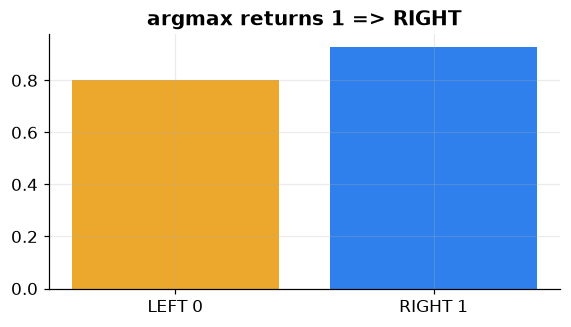

In [4]:
Q=np.zeros((6,2)); Q[3]=[.80,.93]; obs=3
print("Q[3] =",Q[3]); print("argmax =",np.argmax(Q[3]))
plt.figure(figsize=(6,3)); plt.bar(["LEFT 0","RIGHT 1"],Q[3],color=[COLORS["Q"],COLORS["EXPLOIT"]]); plt.title("argmax returns 1 => RIGHT"); plt.show()

Exploration randomness changes **which experience gets collected** and how quickly learning settles. It does not explain the Bellman value `.93` itself.

<div style="border-left:10px solid #ECA82C;background:#16181c;color:#f4f4f5;padding:14px 18px;border-radius:9px;margin:10px 0 14px 0"><div style="font-size:12px;font-weight:900;letter-spacing:.12em;color:#ECA82C">Q</div><div style="font-size:21px;font-weight:800;margin-top:4px">Why ε matters: greedy can get stuck</div><div style="font-size:15px;line-height:1.55;margin-top:8px">Start every Q at -0.5 (a pessimistic guess). In state 0, LEFT (action 0) wins the tie and its estimate only rises toward about -0.4, so it keeps beating the untried RIGHT at -0.5. A pure-greedy agent bumps into the wall until the time limit and never sees the goal. (With a table of zeros, the -0.02 step cost makes tried actions look worse than untried ones, so greedy explores by accident. Do not count on that.)</div></div>

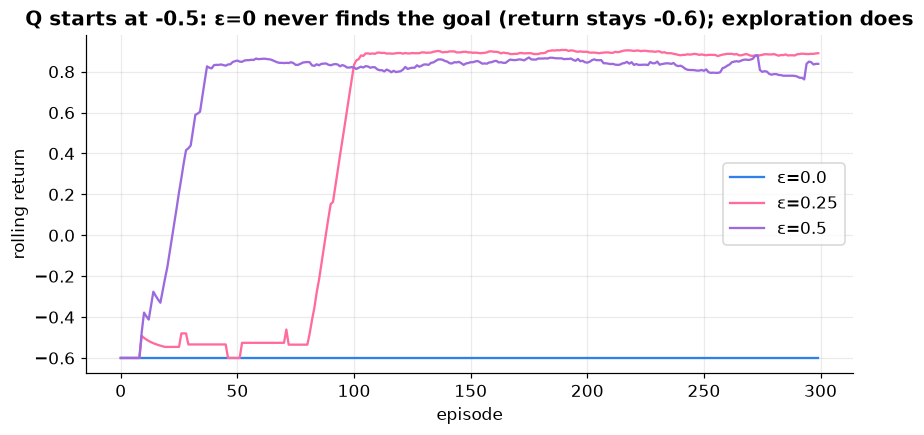

In [5]:
def train(epsilon,q_init=-.5,episodes=300,alpha=.2,gamma=.95,seed=7):
    rng=np.random.default_rng(seed); env=LineWorld(); Q=np.full((6,2),q_init); returns=[]
    for ep in range(episodes):
        obs,_=env.reset(); total=0
        while True:
            action=int(rng.integers(0,2)) if rng.random()<epsilon else int(np.argmax(Q[obs]))
            n,r,term,trunc,_=env.step(action); future=0 if term else np.max(Q[n])
            Q[obs,action]+=alpha*(r+gamma*future-Q[obs,action]); total+=r; obs=n
            if term or trunc: break
        returns.append(total)
    return Q,returns
plt.figure(figsize=(9,4))
for eps,key in [(0.0,"EXPLOIT"),(.25,"EPSILON"),(.5,"EXPLORE")]:
    _,ret=train(eps); plt.plot(pd.Series(ret).rolling(20,min_periods=1).mean(),label=f"ε={eps}",color=COLORS[key])
plt.xlabel("episode"); plt.ylabel("rolling return"); plt.title("Q starts at -0.5: ε=0 never finds the goal (return stays -0.6); exploration does"); plt.legend(); plt.show()

<div style="border-left:10px solid #FF6B9A;background:#16181c;color:#f4f4f5;padding:14px 18px;border-radius:9px;margin:10px 0 14px 0"><div style="font-size:12px;font-weight:900;letter-spacing:.12em;color:#FF6B9A">EPSILON</div><div style="font-size:21px;font-weight:800;margin-top:4px">Takeaway</div><div style="font-size:15px;line-height:1.55;margin-top:8px">Exploit uses the table. Explore fills in the table. ε sets the mix. Next: 00.06 walks one full episode line by line.</div></div>